# 04 - Feature Engineering

In this notebook I build the 11 features chosen in the EDA (notebook 03) and split the data into train, validation and test.

### 1. Import libraries and load the clean data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import holidays

processed_folder = "../datasets/processed"
figures_folder = "../results/figures"

data = pd.read_csv(processed_folder + "/gb_clean_2015_2019.csv")
data["time"] = pd.to_datetime(data["time"], utc=True)

print("Rows:", len(data))

Rows: 43824


### 2. Past load features

All of them use only **past** values, so the model never sees the hour it is forecasting.

In [2]:
data["lag_1"] = data["load"].shift(1)        # 1 hour before
data["lag_24"] = data["load"].shift(24)      # same hour yesterday
data["lag_168"] = data["load"].shift(168)    # same hour last week

# shift(1) first, so the current hour is not used in the average
data["rolling_mean_24"] = data["load"].shift(1).rolling(24).mean()     # average of the last day
data["rolling_mean_168"] = data["load"].shift(1).rolling(168).mean()   # average of the last week

### 3. Calendar features
The data is in UTC, so I convert to UK time first.

In [3]:
uk_time = data["time"].dt.tz_convert("Europe/London")

data["hour"] = uk_time.dt.hour
data["day_of_week"] = uk_time.dt.dayofweek
data["month"] = uk_time.dt.month
data["is_weekend"] = (data["day_of_week"] >= 5).astype(int)

uk_holidays = holidays.UK(subdiv="ENG", years=[2015, 2016, 2017, 2018, 2019])
data["is_holiday"] = uk_time.dt.date.isin(list(uk_holidays.keys())).astype(int)

print("Holiday hours:", data["is_holiday"].sum())

Holiday hours: 1032


### 4. Temperature
`temperature` is already a column, so it is used as it is.

### 5. Remove the first week
The first 168 hours have no `lag_168` and no `rolling_mean_168` because there is no earlier data.

In [4]:
print("Rows before:", len(data))
data = data.dropna().reset_index(drop=True)
print("Rows after :", len(data))
print("Data now starts at", data["time"].iloc[0])

Rows before: 43824
Rows after : 43656
Data now starts at 2015-01-08 00:00:00+00:00


In [5]:
columns = ["time", "load",
           "lag_1", "lag_24", "lag_168", "rolling_mean_24", "rolling_mean_168",
           "hour", "day_of_week", "month", "is_weekend", "is_holiday",
           "temperature", "was_filled"]
data = data[columns]

data.head()

,time,load,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168,hour,day_of_week,month,is_weekend,is_holiday,temperature,was_filled
0,2015-01-08 00:00:00+00:00,32593.0,35918.0,32698.0,26758.0,42146.500000,35180.613095,0,3,1,0,0,8.582,0
1,2015-01-08 01:00:00+00:00,31607.0,32593.0,32413.0,27166.0,42142.125000,35215.345238,1,3,1,0,0,8.491,0
2,2015-01-08 02:00:00+00:00,30136.0,31607.0,30988.0,24472.0,42108.541667,35241.779762,2,3,1,0,0,8.333,0
3,2015-01-08 03:00:00+00:00,29286.0,30136.0,30064.0,23003.0,42073.041667,35275.494048,3,3,1,0,0,8.099,0
4,2015-01-08 04:00:00+00:00,27746.0,29286.0,28297.0,21832.0,42040.625000,35312.892857,4,3,1,0,0,7.862,0


### 6. Check the features

In [6]:
# example: Christmas 2019
data[(data["time"] >= "2019-12-24 20:00") & (data["time"] <= "2019-12-25 03:00")]

,time,load,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168,hour,day_of_week,month,is_weekend,is_holiday,temperature,was_filled
43484,2019-12-24 20:00:00+00:00,37350.0,39385.0,40048.0,45604.0,36002.125000,37450.955357,20,1,12,0,0,6.503,0
43485,2019-12-24 21:00:00+00:00,34708.0,37350.0,37527.0,41914.0,35889.708333,37401.824405,21,1,12,0,0,6.154,0
43486,2019-12-24 22:00:00+00:00,31613.0,34708.0,34395.0,37552.0,35772.250000,37358.931548,22,1,12,0,0,5.762,0
43487,2019-12-24 23:00:00+00:00,28458.0,31613.0,31204.0,34050.0,35656.333333,37323.580357,23,1,12,0,0,5.472,0
43488,2019-12-25 00:00:00+00:00,27790.0,28458.0,30460.0,33594.0,35541.916667,37290.294643,0,2,12,0,1,5.260,0
43489,2019-12-25 01:00:00+00:00,26507.0,27790.0,29968.0,32844.0,35430.666667,37255.747024,1,2,12,0,1,4.940,0
43490,2019-12-25 02:00:00+00:00,24581.0,26507.0,28504.0,31543.0,35286.458333,37218.026786,2,2,12,0,1,4.532,0
43491,2019-12-25 03:00:00+00:00,23007.0,24581.0,26867.0,30902.0,35123.000000,37176.586310,3,2,12,0,1,4.249,0


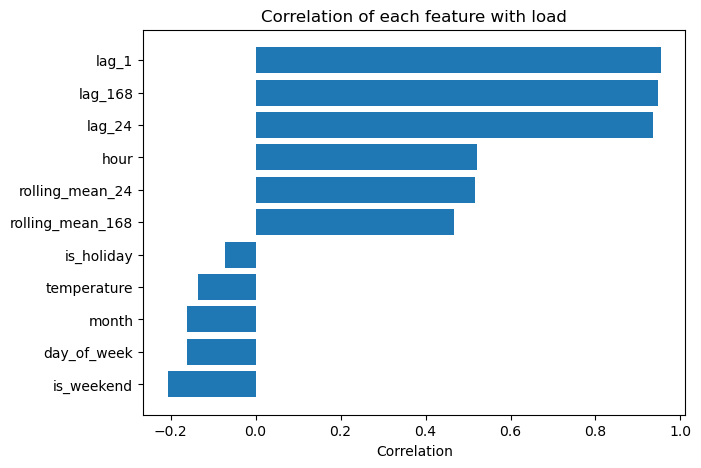

is_weekend         -0.207
day_of_week        -0.163
month              -0.161
temperature        -0.135
is_holiday         -0.073
rolling_mean_168    0.467
rolling_mean_24     0.517
hour                0.521
lag_24              0.936
lag_168             0.948
lag_1               0.954
Name: load, dtype: float64


In [7]:
features = ["lag_1", "lag_24", "lag_168", "rolling_mean_24", "rolling_mean_168",
            "hour", "day_of_week", "month", "is_weekend", "is_holiday", "temperature"]

correlation = data[features + ["load"]].corr()["load"].drop("load")
correlation = correlation.sort_values()

plt.figure(figsize=(7, 5))
plt.barh(correlation.index, correlation.values)
plt.title("Correlation of each feature with load")
plt.xlabel("Correlation")
plt.savefig(figures_folder + "/04_feature_correlation.png")
plt.show()

print(correlation.round(3))

This is only a first check. The real importance of each feature is tested later with the ablation study (RQ4).

### 7. Split by time
The split is by year, never random, so the models never see the future.

In [8]:
train = data[data["time"] < "2018-01-01"]
validation = data[(data["time"] >= "2018-01-01") & (data["time"] < "2019-01-01")]
test = data[data["time"] >= "2019-01-01"]

print("Train      :", len(train), "rows,", train["time"].iloc[0].date(), "to", train["time"].iloc[-1].date())
print("Validation :", len(validation), "rows,", validation["time"].iloc[0].date(), "to", validation["time"].iloc[-1].date())
print("Test       :", len(test), "rows,", test["time"].iloc[0].date(), "to", test["time"].iloc[-1].date())

Train      : 26136 rows, 2015-01-08 to 2017-12-31
Validation : 8760 rows, 2018-01-01 to 2018-12-31
Test       : 8760 rows, 2019-01-01 to 2019-12-31


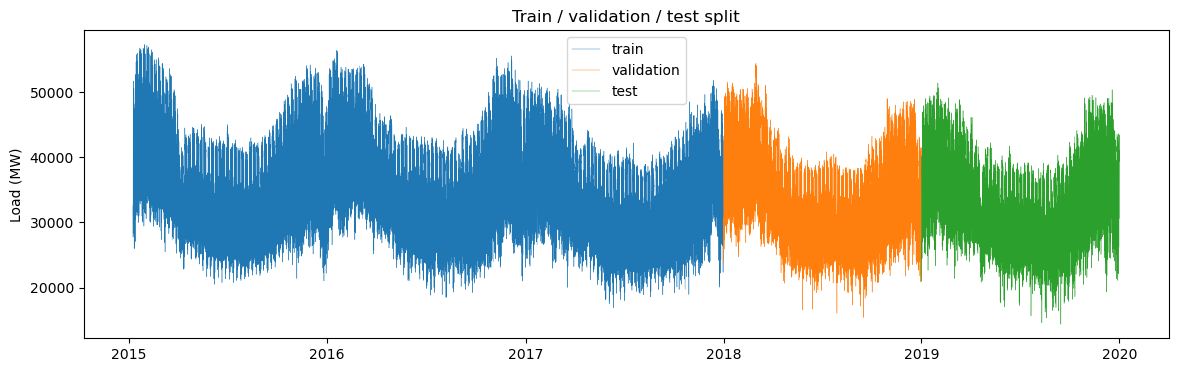

In [9]:
plt.figure(figsize=(14, 4))
plt.plot(train["time"], train["load"], linewidth=0.3, label="train")
plt.plot(validation["time"], validation["load"], linewidth=0.3, label="validation")
plt.plot(test["time"], test["load"], linewidth=0.3, label="test")
plt.title("Train / validation / test split")
plt.ylabel("Load (MW)")
plt.legend()
plt.savefig(figures_folder + "/04_split.png")
plt.show()

### 8. Save

In [10]:
data.to_csv(processed_folder + "/gb_features_2015_2019.csv", index=False)
train.to_csv(processed_folder + "/train.csv", index=False)
validation.to_csv(processed_folder + "/validation.csv", index=False)
test.to_csv(processed_folder + "/test.csv", index=False)

print("Saved 4 files")

Saved 4 files


### Summary

- 11 features: 5 past-load, 5 calendar, 1 temperature
- First week removed (no `lag_168` yet)
- Train 2015-2017, validation 2018, test 2019
- Files: `gb_features_2015_2019.csv`, `train.csv`, `validation.csv`, `test.csv`

**Next:** notebook 05 - seasonal naive and SARIMA models.